# Profile HMM for the Kunitz/BPTI domain (PF00014)

Laboratory of Bioinformatics 1, University of Bologna.

This notebook runs the whole project from data collection to validation:

| Step | Folder | What happens |
|---|---|---|
| 00 | `00_data_collection` | RCSB PDB search: Pfam PF00014, data collection resolution ≤ 3.5 Å, entity length 40–80 |
| 01 | `01_clustering` | MMseqs2 redundancy reduction (identity ≥ 0.95, coverage ≥ 0.9, `--cov-mode 1`) |
| 02 | `02_structural_alignment` | Chain extraction, mTM-align, structural outlier removal (avg TM-score ≤ 0.5 or avg RMSD ≥ 2 Å) |
| 03 | `03_hmm_build` | `hmmbuild` / `hmmstat`, consensus and conserved cysteines |
| 04 | `04_validation` | UniProt/Swiss-Prot positives and negatives, BLAST removal of training-like positives, `hmmsearch`, 2-fold cross-validation, figures |

**How to run:** on Google Colab, open the notebook and run all cells; the first code cell installs the tools. On your own computer, create the conda environment and compile mTM-align as described in `README.md`, start Jupyter in the project folder and run all cells.

**Reproducibility:** every step writes its results to its folder and is skipped on the next run if those files already exist (set `FORCE = True` to recompute). The PDB query date, the UniProt release and all tool versions are written to `run_metadata.json`. To reproduce an earlier run exactly, keep its `00_data_collection/pdb_kunitz.fasta` and the two UniProt FASTA files in `04_validation/`; the databases change over time, the files do not.

## Google Colab only: install the tools

On Colab this cell installs HMMER and BLAST (Ubuntu packages), MMseqs2 (release 18-8cc5c) and mTM-align (compiled from source), and moves into the project folder. With `USE_DRIVE = True` the project folder is on your Google Drive, so the results survive the end of the Colab session (Colab asks for permission once). On your own computer this cell does nothing; use the conda environment from `README.md` instead.

The tools are reinstalled in every new Colab session (about one minute); the project files on Drive are kept, so finished steps are skipped.

In [1]:
import os
import shutil
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = False                         # Colab: keep the project on Google Drive
COLAB_PROJECT = "kunitz_hmm_project"     # folder name on Drive (or under /content)
COLAB_ROOT = Path("/content")


def sh(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)


if IN_COLAB:
    if USE_DRIVE:
        from google.colab import drive
        drive.mount(str(COLAB_ROOT / "drive"))
        project_dir = COLAB_ROOT / "drive" / "MyDrive" / COLAB_PROJECT
    else:
        project_dir = COLAB_ROOT / COLAB_PROJECT
    project_dir.mkdir(parents=True, exist_ok=True)
    os.chdir(project_dir)

    tools = COLAB_ROOT / "tools"
    tools.mkdir(exist_ok=True)

    # HMMER and BLAST+
    if not (shutil.which("hmmbuild") and shutil.which("blastp")):
        sh("apt-get -qq update > /dev/null && apt-get -qq install -y hmmer ncbi-blast+ > /dev/null")

    # MMseqs2, same release as environment.yml
    mmseqs_bin = tools / "mmseqs" / "bin"
    if not (mmseqs_bin / "mmseqs").exists():
        flavour = "avx2" if " avx2 " in open("/proc/cpuinfo").read() else "sse41"
        sh(f"wget -q -O {tools}/mmseqs.tar.gz https://github.com/soedinglab/MMseqs2/"
           f"releases/download/18-8cc5c/mmseqs-linux-{flavour}.tar.gz")
        sh(f"tar xzf {tools}/mmseqs.tar.gz -C {tools}")
    os.environ["PATH"] = f"{mmseqs_bin}:{os.environ["PATH"]}"

    # mTM-align from source (no changes needed on Linux)
    mtm_bin = tools / "mTM-align-code" / "src" / "mTM-align"
    if not mtm_bin.exists() or subprocess.run([mtm_bin, "-h"], capture_output=True).returncode == 126:
        sh(f"wget -q -O {tools}/mTM-align.tar.bz2 https://yanglab.qd.sdu.edu.cn/mTM-align/mTM-align.tar.bz2")
        sh(f"tar xjf {tools}/mTM-align.tar.bz2 -C {tools}")
        sh(f"cd {mtm_bin.parent} && make clean > /dev/null && make > make.log 2>&1")
    os.environ["MTM"] = str(mtm_bin)

    print("\nproject folder:", Path.cwd())
    for t in ("mmseqs", "hmmbuild", "hmmsearch", "blastp"):
        print(f"{t:10s}", shutil.which(t))
    print(f"{'mTM-align':10s}", mtm_bin)
else:
    print("Not running on Colab: nothing to install. Project folder:", Path.cwd())


project folder: /content/kunitz_hmm_project
mmseqs     /content/tools/mmseqs/bin/mmseqs
hmmbuild   /usr/bin/hmmbuild
hmmsearch  /usr/bin/hmmsearch
blastp     /usr/bin/blastp
mTM-align  /content/tools/mTM-align-code/src/mTM-align


## Setup: parameters, folders, tool check

In [2]:
import csv
import gzip
import json
import math
import os
import platform
import random
import re
import shutil
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from matplotlib.colors import LinearSegmentedColormap, LogNorm

# ---------------- parameters (all choices of the project are here)
PFAM_ID = "PF00014"
MAX_RESOLUTION = 3.5            # data collection resolution, Angstrom
MIN_LEN, MAX_LEN = 40, 80       # polymer entity sequence length

MIN_SEQ_ID = 0.95               # MMseqs2
COVERAGE = 0.9
COV_MODE = 1

TM_MAX = 0.5                    # structural outlier: avg TM-score <= TM_MAX
RMSD_MIN = 2.0                  #                  or avg RMSD (A) >= RMSD_MIN

BLAST_MIN_ID = 95               # positives with identity >= 95 % over >= 50 residues
BLAST_MIN_LEN = 50              # to a training sequence are removed from the test set

HMMSEARCH_Z = 1000              # fixed database size -> comparable E-values
MISSING_EVALUE = 10.0           # E-value given to sequences hmmsearch does not report
SEED = 42                       # random split into two folds
THRESHOLDS = [10.0 ** -k for k in range(1, 16)]          # 1e-1 ... 1e-15

CPU = os.cpu_count() or 4

# use the tools of the environment this kernel runs in, even if it was not "activated"
# (e.g. a conda env selected as kernel in VS Code or Jupyter)
ENV_BIN = Path(sys.executable).parent
os.environ["PATH"] = str(ENV_BIN) + os.pathsep + os.environ.get("PATH", "")

MTM = (os.environ.get("MTM") or shutil.which("mTM-align")
       or str(Path.home() / "tools/mTM-align-code/src/mTM-align"))
FORCE = False                   # True = recompute every step even if its outputs exist

# ---------------- folders
PROJECT = Path.cwd()
D00, D01, D02, D03, D04 = (PROJECT / d for d in (
    "00_data_collection", "01_clustering", "02_structural_alignment",
    "03_hmm_build", "04_validation"))
for d in (D00, D01, D02, D03, D04):
    d.mkdir(exist_ok=True)

# ---------------- helpers
def run(cmd, cwd=None, stdout=None):
    """Run a command list; raise with its output if it fails."""
    res = subprocess.run([str(c) for c in cmd], cwd=cwd, text=True,
                         stdout=stdout or subprocess.PIPE, stderr=subprocess.PIPE)
    if res.returncode != 0:
        raise RuntimeError(f"{' '.join(map(str, cmd))} failed:\n{res.stderr[-2000:]}")
    return res.stdout


def ready(*paths):
    """True when every output exists and FORCE is off -> the step can be skipped."""
    return not FORCE and all(Path(p).exists() and Path(p).stat().st_size > 0 for p in paths)


def count_fasta(path):
    with open(path) as f:
        return sum(1 for line in f if line.startswith(">"))


META_FILE = PROJECT / "run_metadata.json"
META = json.loads(META_FILE.read_text()) if META_FILE.exists() else {}


def save_meta(**kv):
    META.update(kv)
    META_FILE.write_text(json.dumps(META, indent=2))


# ---------------- tool check and versions
tools = {"mmseqs": shutil.which("mmseqs"), "hmmbuild": shutil.which("hmmbuild"),
         "hmmsearch": shutil.which("hmmsearch"), "blastp": shutil.which("blastp"),
         "mTM-align": MTM if Path(MTM).is_file() and os.access(MTM, os.X_OK) else None}
missing = [t for t, p in tools.items() if not p]
if missing:
    raise SystemExit(
        f"Missing tools: {missing}\n"
        f"  kernel Python : {sys.executable}\n"
        f"  searched PATH : {ENV_BIN} (+ system PATH)\n"
        f"  mTM-align     : {MTM}\n"
        "On Google Colab: run the installation cell above first. On your own computer: "
        "select the 'kunitz-hmm' conda environment as the kernel (or start Jupyter after "
        "'conda activate kunitz-hmm'); for mTM-align set MTM=/path/to/mTM-align. See README.md.")

mtm_banner = subprocess.run([MTM, "-h"], capture_output=True, text=True).stdout
versions = {
    "python": platform.python_version(),
    "mmseqs2": run(["mmseqs", "version"]).strip(),
    "hmmer": re.search(r"HMMER ([\d.]+)", run(["hmmbuild", "-h"])).group(1),
    "blast": run(["blastp", "-version"]).splitlines()[0].split()[-1],
    "mTM-align": (re.search(r"Version (\d+)", mtm_banner) or [None, "unknown"])[1],
    "numpy": np.__version__, "pandas": pd.__version__,
}
save_meta(tool_versions=versions)
pd.Series(versions, name="version").to_frame()

,version
python,3.13.18
mmseqs2,8cc5ce367b5638c4306c2d7cfc652dd099a4643f
hmmer,3.4
blast,2.12.0+
mTM-align,20220104
numpy,2.4.6
pandas,2.2.3


In [3]:
# ---------------- figure style (shared by all plots)
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#dddcd7", "#fcfcfb"
BLUE_RAMP = LinearSegmentedColormap.from_list("blue_ramp", ["#eef5fe", "#86b6ef", "#256abf", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "lines.linewidth": 2, "lines.markersize": 5, "figure.dpi": 100,
})

## 00 · Data collection from RCSB PDB

Advanced search, returned as **polymer entities** (so each hit is the Kunitz chain itself, not another chain of the same complex):
`Identifier = "PF00014" AND Annotation Type = "Pfam" AND Data Collection Resolution ≤ 3.5 AND Polymer Entity Sequence Length = [40 – 80]`.
FASTA headers are `PDBID_CHAIN`, using the first author chain of each entity.

In [4]:
PDB_FASTA = D00 / "pdb_kunitz.fasta"
PDB_CSV = D00 / "pdb_kunitz.csv"


def terminal(attribute, operator, value):
    return {"type": "terminal", "service": "text",
            "parameters": {"attribute": attribute, "operator": operator, "value": value}}


PDB_QUERY = {
    "query": {"type": "group", "logical_operator": "and", "nodes": [
        {"type": "group", "logical_operator": "and", "nodes": [
            terminal("rcsb_polymer_entity_annotation.annotation_id", "exact_match", PFAM_ID),
            terminal("rcsb_polymer_entity_annotation.type", "exact_match", "Pfam")]},
        terminal("rcsb_entry_info.diffrn_resolution_high.value", "less_or_equal", MAX_RESOLUTION),
        terminal("entity_poly.rcsb_sample_sequence_length", "range",
                 {"from": MIN_LEN, "to": MAX_LEN, "include_lower": True, "include_upper": True}),
    ]},
    "return_type": "polymer_entity",
    "request_options": {"return_all_hits": True, "results_content_type": ["experimental"]},
}

PDB_GRAPHQL = """
query ($ids: [String!]!) {
  polymer_entities(entity_ids: $ids) {
    rcsb_id
    entity_poly { pdbx_seq_one_letter_code_can rcsb_sample_sequence_length }
    rcsb_polymer_entity_container_identifiers { entry_id auth_asym_ids }
    entry { rcsb_entry_info { diffrn_resolution_high { value } resolution_combined } }
  }
}"""

if ready(PDB_FASTA, PDB_CSV):
    print("00: using existing", PDB_FASTA.relative_to(PROJECT))
else:
    r = requests.post("https://search.rcsb.org/rcsbsearch/v2/query", json=PDB_QUERY, timeout=60)
    r.raise_for_status()
    ids = [hit["identifier"] for hit in r.json()["result_set"]]
    rows = []
    for i in range(0, len(ids), 200):
        g = requests.post("https://data.rcsb.org/graphql", timeout=120,
                          json={"query": PDB_GRAPHQL, "variables": {"ids": ids[i:i + 200]}})
        g.raise_for_status()
        for e in g.json()["data"]["polymer_entities"]:
            info = e["entry"]["rcsb_entry_info"]
            cid = e["rcsb_polymer_entity_container_identifiers"]
            rows.append({
                "entity_id": e["rcsb_id"], "pdb_id": cid["entry_id"],
                "chains": ",".join(cid["auth_asym_ids"]),
                "data_collection_resolution": (info.get("diffrn_resolution_high") or {}).get("value"),
                "refinement_resolution": (info.get("resolution_combined") or [None])[0],
                "length": e["entity_poly"]["rcsb_sample_sequence_length"],
                "sequence": e["entity_poly"]["pdbx_seq_one_letter_code_can"].replace("\n", ""),
            })
    pd.DataFrame(rows).to_csv(PDB_CSV, index=False)
    (D00 / "pdb_kunitz_ids.txt").write_text("\n".join(ids) + "\n")
    with open(PDB_FASTA, "w") as f:
        for row in rows:
            f.write(f">{row['pdb_id']}_{row['chains'].split(',')[0]}\n{row['sequence']}\n")
    save_meta(pdb_query_date=datetime.now(timezone.utc).isoformat(timespec="seconds"))

pdb = pd.read_csv(PDB_CSV)
save_meta(pdb_entities=len(pdb), pdb_entries=int(pdb.pdb_id.nunique()))
print(f"{len(pdb)} polymer entities from {pdb.pdb_id.nunique()} PDB entries "
      f"(query date: {META.get('pdb_query_date', 'unknown')})")
pdb.head()

00: using existing 00_data_collection/pdb_kunitz.fasta
136 polymer entities from 136 PDB entries (query date: 2026-11-11T17:21:46+00:00)


,entity_id,pdb_id,chains,data_collection_resolution,refinement_resolution,length,sequence
0,1AAP_1,1AAP,"A,B",1.50,1.50,58,VREVCSEQAETGPCRAMISRWYFDVTEGKCAPFFYGGCGGNRNNFD...
1,1B0C_1,1B0C,"A,B,C,D,E",2.80,2.80,58,RPDFCLEPPYTGPCKARIIRYFYNAKAGLCQTFVYGGCRAKRNNFK...
2,1FAN_1,1FAN,A,2.00,2.00,58,RPDFCLEPPYTGPCKARIIRYFYNAKAGLCQTFVYGGCRAKRNNAK...
3,1T7C_2,1T7C,"B,D",1.85,1.85,58,RPDFCLEPPYTGPCEARIIRYFYNAKAGLCQTFVYGGCRAKRNNFK...
4,1T8L_2,1T8L,"B,D",1.75,1.75,59,MRPDFCLEPPYTGPCMARIIRYFYNAKAGLCQTFVYGGCRAKRNNF...


## 01 · Redundancy reduction with MMseqs2

`--cov-mode 1` requires the coverage on the sequence that joins a cluster, so N-terminally truncated chains (e.g. 3FP7_J) are grouped with their full-length counterparts instead of becoming separate representatives.

MMseqs2 clusters greedily, so the result depends on the order of the input sequences, and RCSB does not return hits in a fixed order. The sequences are therefore sorted by their header (`PDBID_CHAIN`) before clustering; the same set of sequences then always gives the same clusters.

In [5]:
CLU = D01 / "pdb_kunitz_clust"
REP_FASTA = D01 / "pdb_kunitz_clust_rep_seq.fasta"
CLU_TSV = D01 / "pdb_kunitz_clust_cluster.tsv"
SORTED_FASTA = D01 / "pdb_kunitz_sorted.fasta"

if ready(REP_FASTA, CLU_TSV):
    print("01: using existing", REP_FASTA.relative_to(PROJECT))
else:
    records, name = {}, None
    for line in open(PDB_FASTA):
        line = line.strip()
        if line.startswith(">"):
            name = line[1:].split()[0]
            records[name] = ""
        elif name:
            records[name] += line
    SORTED_FASTA.write_text("".join(f">{n}\n{records[n]}\n" for n in sorted(records)))
    tmp = D01 / "mmseqs_tmp"
    run(["mmseqs", "easy-cluster", SORTED_FASTA, CLU, tmp, "--min-seq-id", MIN_SEQ_ID,
         "-c", COVERAGE, "--cov-mode", COV_MODE, "-v", "1"])
    shutil.rmtree(tmp, ignore_errors=True)

clusters = pd.read_csv(CLU_TSV, sep="\t", header=None, names=["representative", "member"])
sizes = (clusters.groupby("representative").size().sort_values(ascending=False)
         .rename("members").reset_index())
sizes.to_csv(D01 / "pdb_kunitz_cluster_sizes.tsv", sep="\t", index=False)
save_meta(clusters=len(sizes))
print(f"{count_fasta(PDB_FASTA)} sequences -> {len(sizes)} clusters "
      f"(identity >= {MIN_SEQ_ID}, coverage >= {COVERAGE}, cov-mode {COV_MODE})")
sizes

01: using existing 01_clustering/pdb_kunitz_clust_rep_seq.fasta
136 sequences -> 22 clusters (identity >= 0.95, coverage >= 0.9, cov-mode 1)


,representative,members
0,1F5R_I,91
1,2ZJX_A,9
2,1AAP_A,6
3,1YC0_I,4
4,1KNT_A,3
5,1G6X_A,3
6,5JB4_A,3
7,1YLC_B,2
8,4DTG_K,2
9,1EJM_B,1


## 02 · Multiple structural alignment with mTM-align

Each representative chain is downloaded from RCSB and reduced to that single chain (first model, `ATOM` records, first alternate location). mTM-align aligns all chains; for each chain the average pairwise TM-score and RMSD to the others is computed (self-comparison excluded). Chains with average TM-score ≤ `TM_MAX` or average RMSD ≥ `RMSD_MIN` are removed and the rest is aligned again.

In [6]:
RAW = D02 / "pdb_raw"
CHAINS = D02 / "chains"
RAW.mkdir(exist_ok=True)
CHAINS.mkdir(exist_ok=True)


def extract_chain(pdb_text, chain):
    out = []
    for line in pdb_text.splitlines():
        if line.startswith("ENDMDL"):
            break                                            # first model only
        if line.startswith("ATOM") and line[21] == chain and line[16] in " A":
            out.append(line[:16] + " " + line[17:])          # drop altloc label
    return out + ["TER", "END"]


reps = [line[1:].split()[0] for line in open(REP_FASTA) if line.startswith(">")]
chain_rows = []
for rep in reps:
    pdb_id, chain = rep.split("_", 1)
    raw = RAW / f"{pdb_id}.pdb"
    if not raw.exists():
        r = requests.get(f"https://files.rcsb.org/download/{pdb_id}.pdb", timeout=60)
        r.raise_for_status()
        raw.write_text(r.text)
    lines = extract_chain(raw.read_text(), chain)
    n_ca = sum(1 for l in lines if l.startswith("ATOM") and l[12:16] == " CA ")
    if n_ca:
        (CHAINS / f"{rep}.pdb").write_text("\n".join(lines) + "\n")
    chain_rows.append({"chain": rep, "residues": n_ca})

chain_table = pd.DataFrame(chain_rows)
print(f"{(chain_table.residues > 0).sum()} of {len(chain_table)} chains extracted")
chain_table.set_index("chain").T

22 of 22 chains extracted


chain,1AAP_A,1EJM_B,1F5R_I,1FAK_I,1G6X_A,1KNT_A,1YC0_I,1YLC_B,1ZR0_B,2ZJX_A,...,4DTG_K,4U30_W,4U32_X,5JB4_A,5JB7_A,5NX1_D,5NX3_D,5YW1_I,6BX8_B,6HAR_E
residues,56,58,57,55,58,55,66,52,63,58,...,60,54,54,58,56,42,42,55,55,54


In [7]:
SUMMARY_KEYS = ["Average length", "Lcore", "ccRMSD", "ccTM-score", "Lali", "RMSD", "TM-score"]


def mtm_align(round_dir, names):
    """Run mTM-align on chains/<name>.pdb; return (summary dict, TM matrix, RMSD matrix)."""
    round_dir = Path(round_dir)
    if not ready(round_dir / "result.fasta", round_dir / "pairwise_TMscore.txt"):
        shutil.rmtree(round_dir, ignore_errors=True)
        round_dir.mkdir()
        for n in names:
            shutil.copy(CHAINS / f"{n}.pdb", round_dir)
        (round_dir / "input_list.txt").write_text("\n".join(f"{n}.pdb" for n in names) + "\n")
        with open(round_dir / "mtm_align.log", "w") as log:
            run([MTM, "-i", "input_list.txt", "-outdir", "."], cwd=round_dir, stdout=log)
    summary = {}
    for line in open(round_dir / "mtm_align.log"):
        key, _, value = line.partition(":")
        if key in SUMMARY_KEYS:
            summary[key] = float(value)

    def matrix(fname):
        m = pd.read_csv(round_dir / fname, sep=r"\s+", index_col=0)
        m.index = [i.removesuffix(".pdb") for i in m.index]
        m.columns = [c.removesuffix(".pdb") for c in m.columns]
        return m.loc[names, names]

    return summary, matrix("pairwise_TMscore.txt"), matrix("pairwise_rmsd.txt")


def chain_averages(tm, rmsd):
    off = ~np.eye(len(tm), dtype=bool)
    return pd.DataFrame({
        "avg_TMscore": [tm.values[i][off[i]].mean() for i in range(len(tm))],
        "avg_RMSD": [rmsd.values[i][off[i]].mean() for i in range(len(rmsd))],
    }, index=tm.index)


names1 = chain_table.loc[chain_table.residues > 0, "chain"].tolist()
sum1, tm1, rmsd1 = mtm_align(D02 / "round1_all", names1)
qc1 = chain_averages(tm1, rmsd1).join(chain_table.set_index("chain"))
qc1["outlier"] = (qc1.avg_TMscore <= TM_MAX) | (qc1.avg_RMSD >= RMSD_MIN)
qc1 = qc1.sort_values("avg_TMscore")
qc1.to_csv(D02 / "qc_round1.tsv", sep="\t", float_format="%.4f")

outliers = qc1.index[qc1.outlier].tolist()
(D02 / "outliers.txt").write_text("".join(f"{o}\n" for o in outliers))
if outliers:
    names_final = [n for n in names1 if n not in outliers]
    sum_final, tm_final, rmsd_final = mtm_align(D02 / "round2_filtered", names_final)
    final_dir = D02 / "round2_filtered"
else:
    names_final, sum_final, tm_final, rmsd_final = names1, sum1, tm1, rmsd1
    final_dir = D02 / "round1_all"

# final alignment for hmmbuild: upper case, one line per sequence
seqs, name = {}, None
for line in open(final_dir / "result.fasta"):
    line = line.strip()
    if line.startswith(">"):
        name = line[1:].split()[0].removesuffix(".pdb")
        seqs[name] = ""
    elif name:
        seqs[name] += line.upper()
ALI = D02 / "pdb_kunitz_mtm.ali"
ALI.write_text("".join(f">{n}\n{s}\n" for n, s in seqs.items()))

save_meta(structures_round1=len(names1), structural_outliers=outliers,
          structures_final=len(names_final), mtm_round1=sum1, mtm_final=sum_final,
          alignment_columns=len(next(iter(seqs.values()))))
print(f"Outliers (avg TM-score <= {TM_MAX} or avg RMSD >= {RMSD_MIN} A): {outliers or 'none'}")
print(f"Final alignment: {len(seqs)} sequences, {len(next(iter(seqs.values())))} columns")
display(pd.DataFrame({"round 1 (all)": sum1, "final": sum_final}))
qc1.round(3)

Outliers (avg TM-score <= 0.5 or avg RMSD >= 2.0 A): none
Final alignment: 22 sequences, 92 columns


,round 1 (all),final
Average length,56.454500,56.454500
Lcore,37.000000,37.000000
ccRMSD,0.649716,0.649716
ccTM-score,0.663551,0.663551
Lali,52.108200,52.108200
RMSD,0.753486,0.753486
TM-score,0.911268,0.911268


,avg_TMscore,avg_RMSD,residues,outlier
4U30_W,0.860,1.006,54,False
1KNT_A,0.871,1.036,55,False
5NX3_D,0.896,0.684,42,False
1YLC_B,0.899,0.840,52,False
5NX1_D,0.901,0.683,42,False
1YC0_I,0.902,1.142,66,False
1ZR0_B,0.905,1.039,63,False
6HAR_E,0.916,0.744,54,False
5YW1_I,0.917,0.775,55,False
6BX8_B,0.918,0.774,55,False


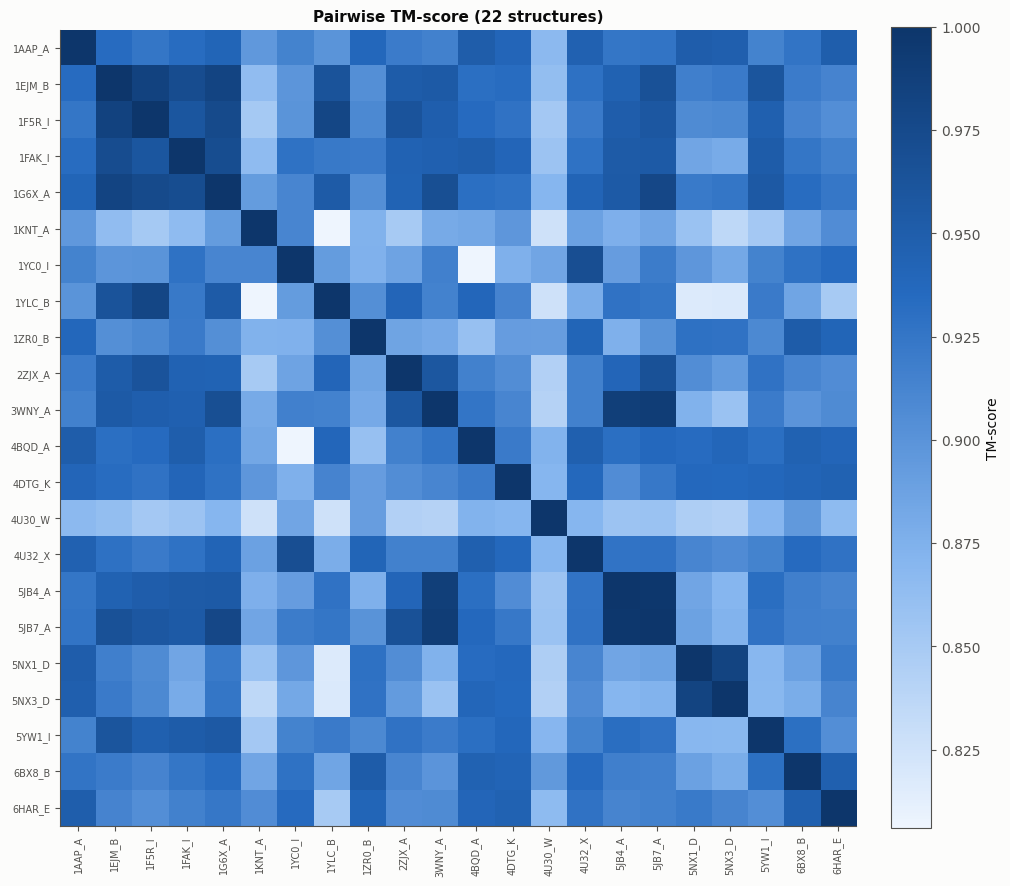

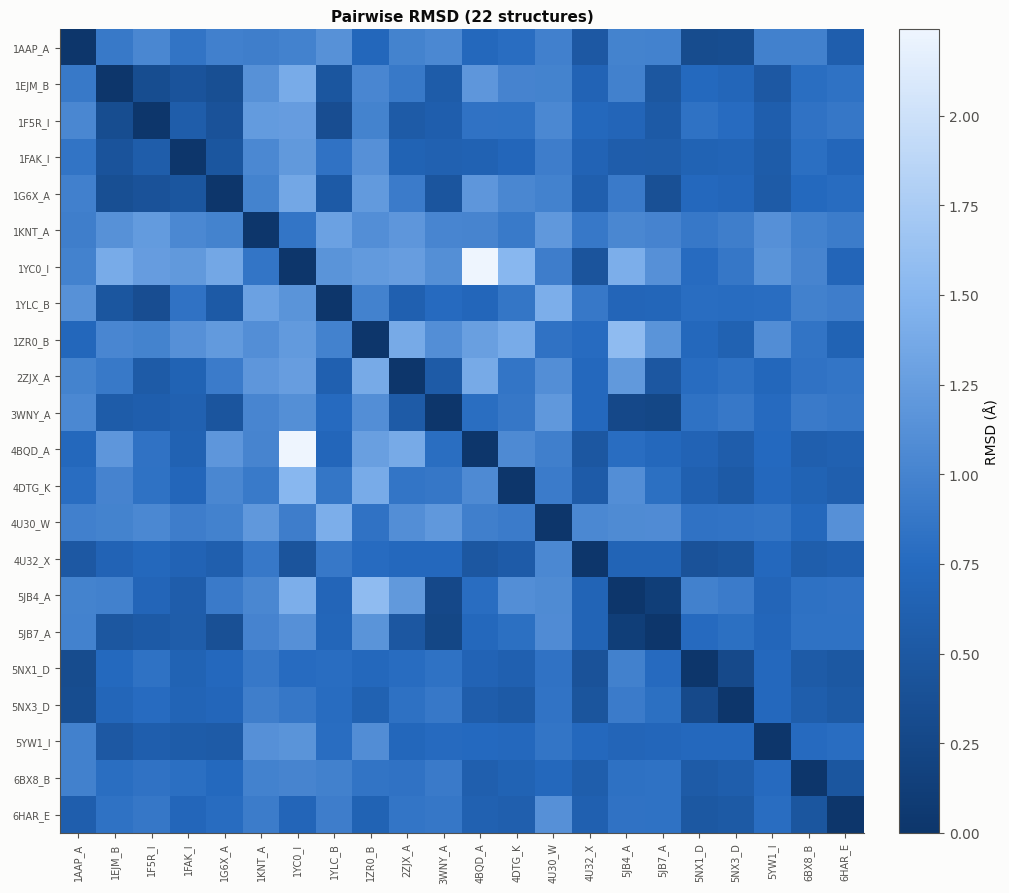

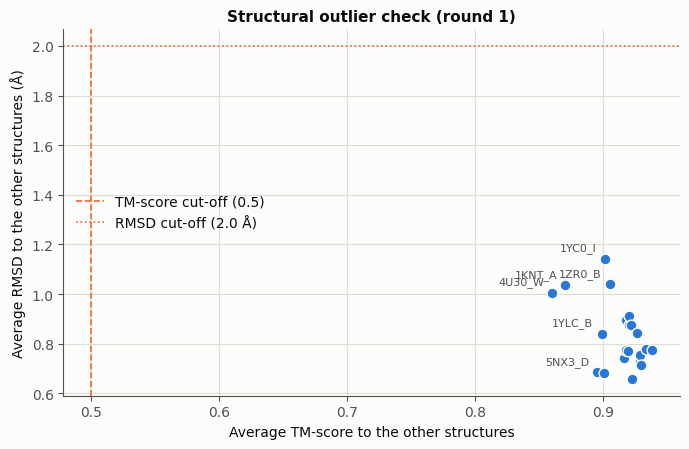

In [8]:
def heatmap(mat, label, title, path, vmin=None, vmax=None, reverse=False):
    n = len(mat)
    fig, ax = plt.subplots(figsize=(0.32 * n + 3, 0.32 * n + 2))
    im = ax.imshow(mat.values, cmap=BLUE_RAMP.reversed() if reverse else BLUE_RAMP,
                   vmin=vmin, vmax=vmax)
    ax.set_xticks(range(n), mat.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(n), mat.index, fontsize=7)
    ax.grid(False)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=label)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.show()


heatmap(tm_final, "TM-score", f"Pairwise TM-score ({len(tm_final)} structures)",
        D02 / "pairwise_tmscore.png")
heatmap(rmsd_final, "RMSD (Å)", f"Pairwise RMSD ({len(rmsd_final)} structures)",
        D02 / "pairwise_rmsd.png", vmin=0, reverse=True)

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.scatter(qc1.avg_TMscore, qc1.avg_RMSD, color=BLUE, edgecolor=SURFACE, s=60, zorder=3)
# label only the structures closest to the cut-offs (lowest TM-score, highest RMSD)
to_label = set(qc1.nsmallest(4, "avg_TMscore").index) | set(qc1.nlargest(3, "avg_RMSD").index)
for name in to_label:
    row = qc1.loc[name]
    ax.annotate(name, (row.avg_TMscore, row.avg_RMSD), fontsize=8, color=MUTED,
                xytext=(-6, 6), textcoords="offset points", ha="right")
ax.axvline(TM_MAX, color=ORANGE, linestyle="--", linewidth=1.2, label=f"TM-score cut-off ({TM_MAX})")
ax.axhline(RMSD_MIN, color=ORANGE, linestyle=":", linewidth=1.2, label=f"RMSD cut-off ({RMSD_MIN} Å)")
ax.set_xlabel("Average TM-score to the other structures")
ax.set_ylabel("Average RMSD to the other structures (Å)")
ax.set_title("Structural outlier check (round 1)")
ax.legend(frameon=False, loc="center left")
fig.tight_layout()
fig.savefig(D02 / "outlier_check.png", dpi=300)
plt.show()

## 03 · Profile HMM

`hmmbuild` on the structural alignment. The consensus line of the model shows the conserved cysteines (upper case = strongly conserved).

In [9]:
HMM = D03 / "pdb_kunitz.hmm"
if ready(HMM):
    print("03: using existing", HMM.relative_to(PROJECT))
else:
    (D03 / "hmmbuild_summary.txt").write_text(
        run(["hmmbuild", "--amino", "--informat", "afa", "-n", "pdb_kunitz", HMM, ALI]))
(D03 / "hmmstat.txt").write_text(run(["hmmstat", HMM]))

header, consensus, in_body = {}, [], False
for line in open(HMM):
    if line.startswith("HMM "):
        in_body = True
        continue
    if not in_body:
        key, _, value = line.partition(" ")
        header[key] = value.strip()
        continue
    fields = line.split()
    if len(fields) >= 26 and fields[0].isdigit():       # match-state emission line
        consensus.append(fields[22])

cons = "".join(consensus)
cys = [i + 1 for i, c in enumerate(cons) if c in "Cc"]
save_meta(hmm_length=int(header["LENG"]), hmm_nseq=int(header["NSEQ"]),
          hmm_effn=float(header["EFFN"]), hmm_consensus=cons, hmm_cysteines=cys)
print(f"Model: {header['LENG']} match states, {header['NSEQ']} sequences, "
      f"effective number {float(header['EFFN']):.2f}")
print("Consensus:", cons)
print("Cysteines at match states:", cys,
      "(upper case:", [i + 1 for i, c in enumerate(cons) if c == "C"], ")")
print("Logo: upload", HMM.relative_to(PROJECT), "to https://skylign.org")

03: using existing 03_hmm_build/pdb_kunitz.hmm
Model: 56 match states, 22 sequences, effective number 1.69
Consensus: rpdfClepkdtGpCraliiryfynakegkcqeFvYGGcegnrNnFeseeeckkvCa
Cysteines at match states: [5, 14, 30, 38, 51, 55] (upper case: [5, 14, 55] )
Logo: upload 03_hmm_build/pdb_kunitz.hmm to https://skylign.org


## 04 · Validation on UniProt/Swiss-Prot

**Datasets.** Positives: reviewed proteins with a PF00014 cross-reference. Negatives: all other reviewed proteins. Both are downloaded from the UniProt REST API (the release is recorded in `run_metadata.json`). If `04_validation/positives.fasta` and `negatives.fasta` already exist, they are used as they are, so an earlier download can be reproduced exactly.

In [10]:
POS_ALL = D04 / "positives.fasta"
NEG = D04 / "negatives.fasta"
UNIPROT_QUERIES = {
    POS_ALL: f"(reviewed:true) AND (xref:pfam-{PFAM_ID})",
    NEG: f"(reviewed:true) NOT (xref:pfam-{PFAM_ID})",
}


def uniprot_download(query, dest):
    url = "https://rest.uniprot.org/uniprotkb/stream"
    params = {"format": "fasta", "compressed": "true", "query": query}
    with requests.get(url, params=params, stream=True, timeout=600) as r:
        r.raise_for_status()
        release = r.headers.get("X-UniProt-Release", "unknown")
        tmp = dest.with_suffix(".fasta.gz.part")
        with open(tmp, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    with gzip.open(tmp, "rt") as src, open(dest, "w") as out:
        shutil.copyfileobj(src, out)
    tmp.unlink()
    return release


for dest, query in UNIPROT_QUERIES.items():
    if dest.exists() and dest.stat().st_size > 0:
        print(f"using existing {dest.name}")
        continue
    print(f"downloading {dest.name}: {query}")
    release = uniprot_download(query, dest)
    save_meta(uniprot_release=release,
              uniprot_download_date=datetime.now(timezone.utc).isoformat(timespec="seconds"))

save_meta(uniprot_positives=count_fasta(POS_ALL), uniprot_negatives=count_fasta(NEG))
print(f"positives: {META['uniprot_positives']}, negatives: {META['uniprot_negatives']}, "
      f"UniProt release: {META.get('uniprot_release', 'unknown (files provided by hand)')}")

using existing positives.fasta
using existing negatives.fasta
positives: 398, negatives: 575675, UniProt release: 2026_04


**Removing training-like positives.** Positives that are ≥ 95 % identical over ≥ 50 residues to one of the sequences used to build the HMM are removed, so the model is not tested on its own training data.

In [11]:
TRAIN = D04 / "train.fasta"
POS = D04 / "positives_clean.fasta"
TRAIN.write_text("".join(f">{n}\n{s.replace('-', '')}\n" for n, s in seqs.items()))

blast_out = D04 / "train_vs_pos.blast"
if not ready(blast_out, POS):
    db = D04 / "blastdb" / "positives"
    run(["makeblastdb", "-in", POS_ALL, "-dbtype", "prot", "-out", db])
    run(["blastp", "-query", TRAIN, "-db", db, "-outfmt", "6", "-evalue", "1e-5",
         "-num_threads", CPU, "-out", blast_out])

blast = pd.read_csv(blast_out, sep="\t", header=None,
                    names=["query", "subject", "pident", "length", "mismatch", "gapopen",
                           "qstart", "qend", "sstart", "send", "evalue", "bitscore"])
removed = sorted(set(blast.loc[(blast.pident >= BLAST_MIN_ID) & (blast.length >= BLAST_MIN_LEN),
                               "subject"]))
(D04 / "to_remove.ids").write_text("".join(f"{r}\n" for r in removed))

keep, kept = False, 0
with open(POS_ALL) as src, open(POS, "w") as out:
    for line in src:
        if line.startswith(">"):
            keep = line[1:].split()[0] not in removed
            kept += keep
        if keep:
            out.write(line)
save_meta(positives_removed=len(removed), positives_test=kept)
print(f"removed {len(removed)} training-like positives, {kept} left for testing")
removed

removed 17 training-like positives, 381 left for testing


['sp|O43278|SPIT1_HUMAN',
 'sp|O43291|SPIT2_HUMAN',
 'sp|P00974|BPT1_BOVIN',
 'sp|P02760|AMBP_HUMAN',
 'sp|P05067|A4_HUMAN',
 'sp|P08592|A4_RAT',
 'sp|P10646|TFPI1_HUMAN',
 'sp|P12023|A4_MOUSE',
 'sp|P12111|CO6A3_HUMAN',
 'sp|P29216|A4_MACMU',
 'sp|P48307|TFPI2_HUMAN',
 'sp|P53601|A4_MACFA',
 'sp|P79307|A4_PIG',
 'sp|Q28864|TFPI1_MACMU',
 'sp|Q5IS80|A4_PANTR',
 'sp|Q60495|A4_CAVPO',
 'sp|Q95241|A4_SAISC']

**hmmsearch.** `--max` turns off the speed filters so that no sequence is skipped; `-Z 1000` fixes the database size so that E-values of the two sets are comparable. The negative search takes a few minutes.

In [12]:
POS_OUT, NEG_OUT = D04 / "pos.out", D04 / "neg.out"
for fasta, out in ((POS, POS_OUT), (NEG, NEG_OUT)):
    if ready(out) and out.stat().st_mtime > HMM.stat().st_mtime:
        print("using existing", out.name)
        continue
    print("hmmsearch on", fasta.name)
    run(["hmmsearch", "--max", "-Z", HMMSEARCH_Z, "--cpu", CPU, "--noali",
         "--tblout", out, "-o", os.devnull, HMM, fasta])


def tblout(path):
    """{target: (full-sequence E-value, best-domain E-value)}"""
    hits = {}
    for line in open(path):
        if line.startswith("#") or not line.strip():
            continue
        f = line.split()
        hits[f[0]] = (float(f[4]), float(f[7]))
    return hits


pos_hits, neg_hits = tblout(POS_OUT), tblout(NEG_OUT)
save_meta(hits_positives=len(pos_hits), hits_negatives=len(neg_hits))
print(f"reported hits: {len(pos_hits)} of {count_fasta(POS)} positives, "
      f"{len(neg_hits)} of {count_fasta(NEG)} negatives (E-value <= 10)")

using existing pos.out
using existing neg.out
reported hits: 381 of 381 positives, 5792 of 575675 negatives (E-value <= 10)


**Two-fold cross-validation.** Sequences not reported by hmmsearch get E-value 10. Positives and negatives are shuffled (seed 42) and split into two halves. On each half the E-value threshold with the highest MCC is chosen (ties: middle of the tied range) and tested on the other half. The final threshold is the geometric mean of the two, rounded to a power of ten. This is done for the full-sequence and for the best-domain E-value.

In [13]:
def fasta_ids(path):
    with open(path) as f:
        return [line[1:].split()[0] for line in f if line.startswith(">")]


def confusion(pos_e, neg_e, t):
    tp = int((pos_e <= t).sum()); fp = int((neg_e <= t).sum())
    return tp, fp, len(neg_e) - fp, len(pos_e) - tp          # TP FP TN FN


def metrics(pos_e, neg_e, t):
    tp, fp, tn, fn = confusion(pos_e, neg_e, t)
    denom = math.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return {"threshold": t, "TP": tp, "FP": fp, "TN": tn, "FN": fn,
            "TPR": tp / (tp + fn) if tp + fn else 0.0,
            "FPR": fp / (fp + tn) if fp + tn else 0.0,
            "precision": tp / (tp + fp) if tp + fp else 0.0,
            "accuracy": (tp + tn) / (tp + fp + tn + fn),
            "MCC": (tp * tn - fp * fn) / denom if denom else 0.0}


def best_threshold(pos_e, neg_e):
    scores = [(metrics(pos_e, neg_e, t)["MCC"], t) for t in THRESHOLDS]
    top = max(m for m, _ in scores)
    tied = [t for m, t in scores if abs(m - top) < 1e-12]
    return tied[len(tied) // 2], top, tied


pos_ids, neg_ids = fasta_ids(POS), fasta_ids(NEG)
rng = random.Random(SEED)
rng.shuffle(pos_ids)
rng.shuffle(neg_ids)
hp, hn = len(pos_ids) // 2, len(neg_ids) // 2
FOLD_IDS = {1: (pos_ids[:hp], neg_ids[:hn]), 2: (pos_ids[hp:], neg_ids[hn:])}

RESULTS = {}
for kind, col in (("full", 0), ("domain", 1)):
    def evals(ids, hits):
        return np.array([hits[i][col] if i in hits else MISSING_EVALUE for i in ids])

    folds = {k: (evals(p, pos_hits), evals(n, neg_hits)) for k, (p, n) in FOLD_IDS.items()}
    rows, chosen = [], []
    for train, test in ((1, 2), (2, 1)):
        thr, top, tied = best_threshold(*folds[train])
        chosen.append(thr)
        for role, k in (("optimisation", train), ("test", test)):
            rows.append({"optimised on": f"fold {train}", "evaluated on": f"fold {k} ({role})",
                         "tied best range": f"{tied[-1]:.0e} – {tied[0]:.0e}",
                         **metrics(*folds[k], thr)})
    final_t = 10.0 ** round(sum(math.log10(t) for t in chosen) / 2)
    all_pos = np.concatenate([folds[1][0], folds[2][0]])
    all_neg = np.concatenate([folds[1][1], folds[2][1]])
    whole = metrics(all_pos, all_neg, final_t)

    all_ids_pos = FOLD_IDS[1][0] + FOLD_IDS[2][0]
    all_ids_neg = FOLD_IDS[1][1] + FOLD_IDS[2][1]
    fn = sorted(((e, i) for i, e in zip(all_ids_pos, all_pos) if e > final_t), reverse=True)
    fp = sorted((e, i) for i, e in zip(all_ids_neg, all_neg) if e <= final_t)
    RESULTS[kind] = {"folds": folds, "cv": pd.DataFrame(rows), "threshold": final_t,
                     "whole": whole, "false_negatives": fn, "false_positives": fp}

    with open(D04 / f"classification_{kind}.tsv", "w") as out:
        out.write("id\tevalue\tlabel\tfold\n")
        for k, (p, n) in FOLD_IDS.items():
            for i, e in zip(p, folds[k][0]):
                out.write(f"{i}\t{e:g}\t1\t{k}\n")
            for i, e in zip(n, folds[k][1]):
                out.write(f"{i}\t{e:g}\t0\t{k}\n")
    save_meta(**{f"validation_{kind}": {
        "threshold": final_t, "thresholds_per_fold": chosen,
        "whole_dataset": {k: v for k, v in whole.items()},
        "test_MCC": [r["MCC"] for r in rows if "test" in r["evaluated on"]],
        "false_negatives": [i for _, i in fn], "false_positives": [i for _, i in fp]}})

print(f"Fold sizes: {[(len(p), len(n)) for p, n in FOLD_IDS.values()]} (positives, negatives)")
for kind in RESULTS:
    w = RESULTS[kind]["whole"]
    print(f"{kind:6s} E-value: threshold {RESULTS[kind]['threshold']:.0e}  "
          f"TP={w['TP']} FP={w['FP']} FN={w['FN']} TN={w['TN']}  MCC={w['MCC']:.4f}")

Fold sizes: [(190, 287837), (191, 287838)] (positives, negatives)
full   E-value: threshold 1e-06  TP=376 FP=1 FN=5 TN=575674  MCC=0.9921
domain E-value: threshold 1e-06  TP=375 FP=1 FN=6 TN=575674  MCC=0.9908


In [14]:
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
for kind, res in RESULTS.items():
    print(f"\n=== {kind} E-value: cross-validation")
    display(res["cv"][["optimised on", "evaluated on", "tied best range", "threshold",
                       "TP", "FP", "TN", "FN", "precision", "TPR", "MCC"]])
    print(f"False negatives at {res['threshold']:.0e} (PF00014 proteins the model misses):")
    display(pd.DataFrame(res["false_negatives"], columns=["E-value", "UniProt"]))
    print(f"False positives at {res['threshold']:.0e} (non-PF00014 proteins the model accepts):")
    display(pd.DataFrame(res["false_positives"], columns=["E-value", "UniProt"]))


=== full E-value: cross-validation


,optimised on,evaluated on,tied best range,threshold,TP,FP,TN,FN,precision,TPR,MCC
0,fold 1,fold 1 (optimisation),1e-05 – 1e-05,1e-05,189,0,287837,1,1,0.9947,0.9974
1,fold 1,fold 2 (test),1e-05 – 1e-05,1e-05,188,1,287837,3,0.9947,0.9843,0.9895
2,fold 2,fold 2 (optimisation),1e-09 – 1e-07,1e-08,188,0,287838,3,1,0.9843,0.9921
3,fold 2,fold 1 (test),1e-09 – 1e-07,1e-08,187,0,287837,3,1,0.9842,0.9921


False negatives at 1e-06 (PF00014 proteins the model misses):


,E-value,UniProt
0,4.8,sp|D3GGZ8|BLI5_HAECO
1,1,sp|O62247|BLI5_CAEEL
2,0.0016,sp|A0A1Q1NL17|HA11_HYAAI
3,0.0002,sp|Q8WPG5|KUNI_ORNKA
4,2.7e-06,sp|P86963|KCP2_PINMA


False positives at 1e-06 (non-PF00014 proteins the model accepts):


,E-value,UniProt
0,8.4e-07,sp|P84555|TIQ7_RHISA


... (2 outputs left out)

False negatives at 1e-06 (PF00014 proteins the model misses):


,E-value,UniProt
0,0.33,sp|D3GGZ8|BLI5_HAECO
1,0.048,sp|O62247|BLI5_CAEEL
2,0.0037,sp|A0A1Q1NL17|HA11_HYAAI
3,0.00048,sp|Q8WPG5|KUNI_ORNKA
4,1.1e-05,sp|Q8MVC4|TFPIL_IXOSC
5,5e-06,sp|P86963|KCP2_PINMA


False positives at 1e-06 (non-PF00014 proteins the model accepts):


,E-value,UniProt
0,8.4e-07,sp|P84555|TIQ7_RHISA


**Figures** (saved in `04_validation/` at 300 dpi): confusion matrices per fold and for the whole set, a semi-log ROC curve, false positives / false negatives across thresholds, and MCC across thresholds for both folds.

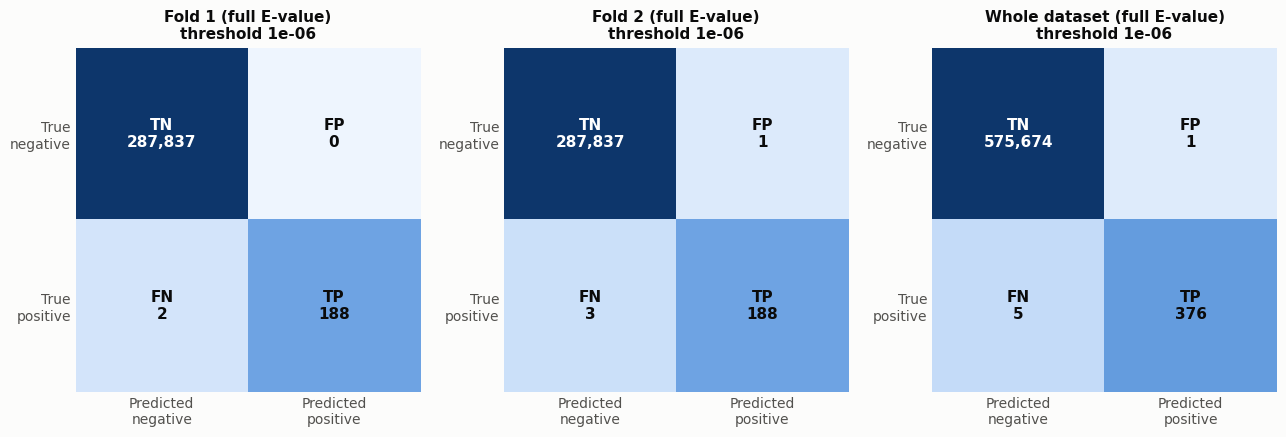

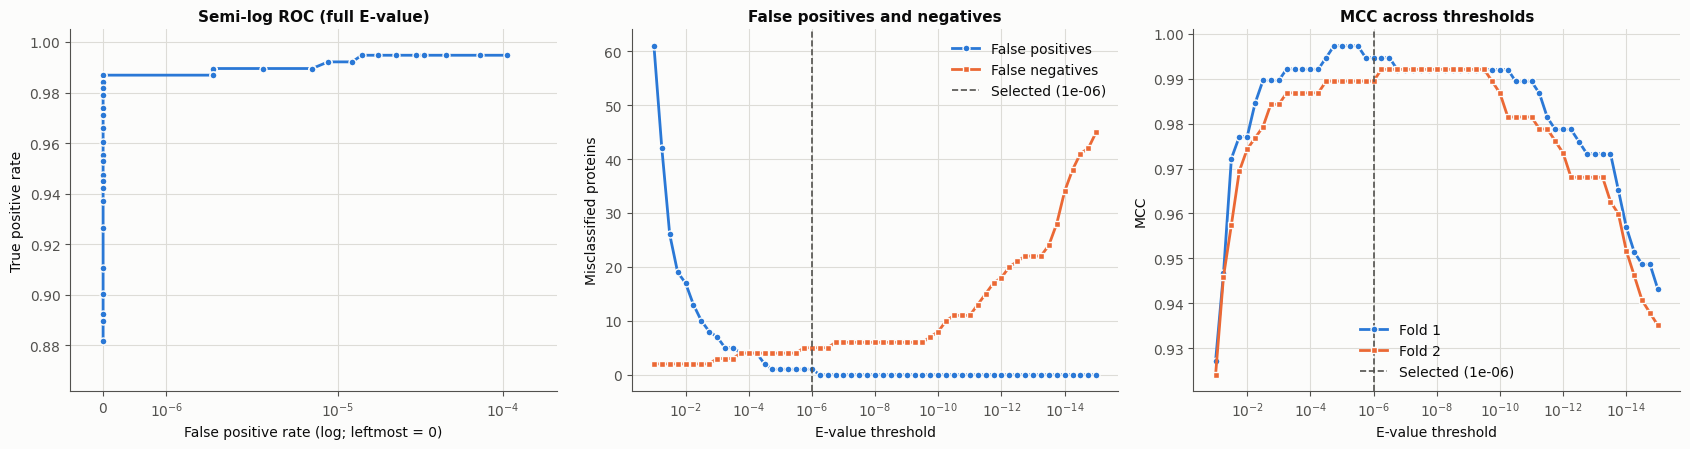

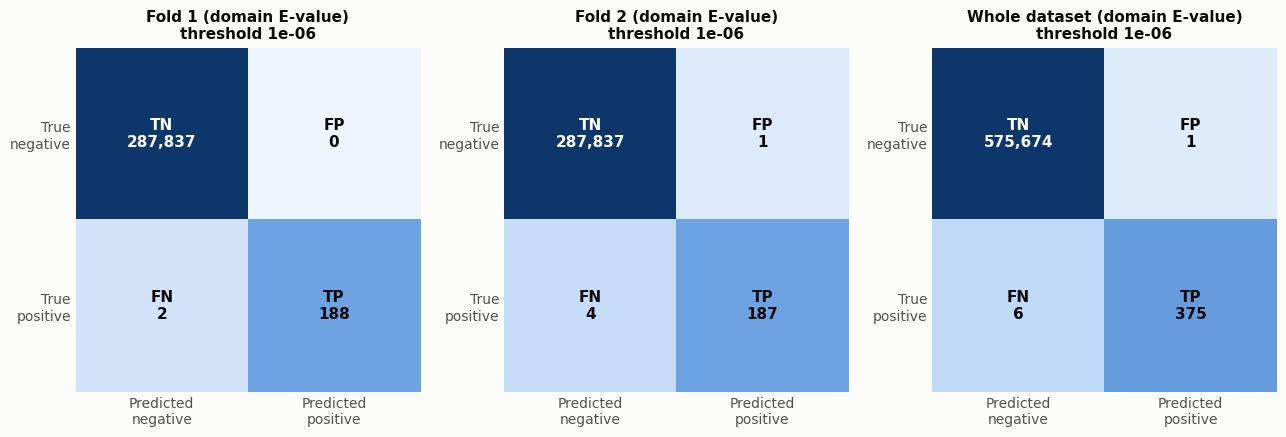

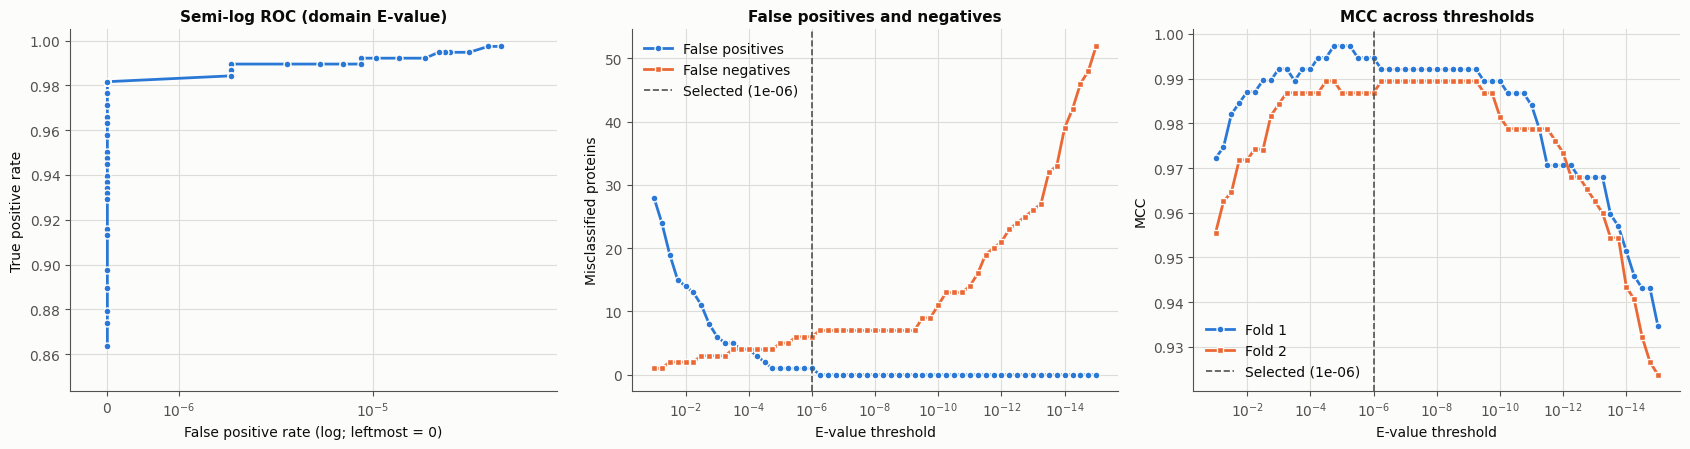

In [15]:
PLOT_THRESHOLDS = [10.0 ** -k for k in np.arange(1, 15.01, 0.25)]


def plot_confusion(pos_e, neg_e, t, title, path, ax):
    tp, fp, tn, fn = confusion(pos_e, neg_e, t)
    cm = np.array([[tn, fp], [fn, tp]])
    ax.imshow(cm + 1, cmap=BLUE_RAMP, norm=LogNorm(vmin=1, vmax=cm.max() + 1))
    ax.set_xticks([0, 1], ["Predicted\nnegative", "Predicted\npositive"])
    ax.set_yticks([0, 1], ["True\nnegative", "True\npositive"])
    ax.tick_params(length=0)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for i, j, label in ((0, 0, "TN"), (0, 1, "FP"), (1, 0, "FN"), (1, 1, "TP")):
        dark = np.log(cm[i, j] + 1) > 0.55 * np.log(cm.max() + 1)
        ax.text(j, i, f"{label}\n{cm[i, j]:,}", ha="center", va="center",
                color="white" if dark else INK, fontsize=11, fontweight="bold")
    ax.set_title(f"{title}\nthreshold {t:.0e}")


for kind, res in RESULTS.items():
    t = res["threshold"]
    (p1, n1), (p2, n2) = res["folds"][1], res["folds"][2]
    pall, nall = np.concatenate([p1, p2]), np.concatenate([n1, n2])

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
    for ax, (pe, ne, title) in zip(axes, ((p1, n1, "Fold 1"), (p2, n2, "Fold 2"),
                                          (pall, nall, "Whole dataset"))):
        plot_confusion(pe, ne, t, f"{title} ({kind} E-value)", None, ax)
    fig.tight_layout()
    fig.savefig(D04 / f"{kind}_confusion_matrices.png", dpi=300)
    plt.show()

    sweep = pd.DataFrame([metrics(pall, nall, x) for x in PLOT_THRESHOLDS])
    sweep_f1 = pd.DataFrame([metrics(p1, n1, x) for x in PLOT_THRESHOLDS])
    sweep_f2 = pd.DataFrame([metrics(p2, n2, x) for x in PLOT_THRESHOLDS])
    sweep.to_csv(D04 / f"{kind}_metrics_by_threshold.csv", index=False)

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    ax = axes[0]                                                  # semi-log ROC
    one_fp = 1.0 / len(nall)
    ax.plot(sweep.FPR, sweep.TPR, color=BLUE, marker="o", markeredgecolor=SURFACE)
    ax.set_xscale("symlog", linthresh=one_fp, linscale=0.6)
    ax.set_xlim(-0.3 * one_fp, max(sweep.FPR.max() * 2, 10 * one_fp))
    ax.set_ylim(min(0.9, sweep.TPR.min() - 0.02), 1.005)
    ax.set_xlabel("False positive rate (log; leftmost = 0)")
    ax.set_ylabel("True positive rate")
    ax.set_title(f"Semi-log ROC ({kind} E-value)")

    ax = axes[1]                                                  # FP / FN trade-off
    ax.semilogx(sweep.threshold, sweep.FP, color=BLUE, marker="o", markeredgecolor=SURFACE,
                label="False positives")
    ax.semilogx(sweep.threshold, sweep.FN, color=ORANGE, marker="s", markeredgecolor=SURFACE,
                label="False negatives")
    ax.axvline(t, color=MUTED, linestyle="--", linewidth=1.2, label=f"Selected ({t:.0e})")
    ax.invert_xaxis()
    ax.set_xlabel("E-value threshold")
    ax.set_ylabel("Misclassified proteins")
    ax.set_title("False positives and negatives")
    ax.legend(frameon=False)

    ax = axes[2]                                                  # MCC per fold
    ax.semilogx(sweep_f1.threshold, sweep_f1.MCC, color=BLUE, marker="o",
                markeredgecolor=SURFACE, label="Fold 1")
    ax.semilogx(sweep_f2.threshold, sweep_f2.MCC, color=ORANGE, marker="s",
                markeredgecolor=SURFACE, label="Fold 2")
    ax.axvline(t, color=MUTED, linestyle="--", linewidth=1.2, label=f"Selected ({t:.0e})")
    ax.invert_xaxis()
    ax.set_xlabel("E-value threshold")
    ax.set_ylabel("MCC")
    ax.set_title("MCC across thresholds")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(D04 / f"{kind}_roc_fpfn_mcc.png", dpi=300)
    plt.show()

### Threshold stability

The two folds above come from one random split (seed 42). To see how much the selected threshold depends on that split, the whole cross-validation (best MCC on each fold, test on the other, geometric mean) is repeated on `STABILITY_REPEATS` random splits. The tables show how often each threshold is selected and the distribution of the test-fold MCC.


=== full E-value, 1000 random splits
test-fold MCC: mean 0.9912 ± 0.0041 (min 0.9765, max 1.0000)


,selected on one fold (%),final threshold (%)
1e-09,2.8,0
1e-08,11.7,0
1e-07,8.8,5
1e-06,21.6,80.8
1e-05,49.4,5.9
1e-04,0.4,8.3
1e-03,5.2,0


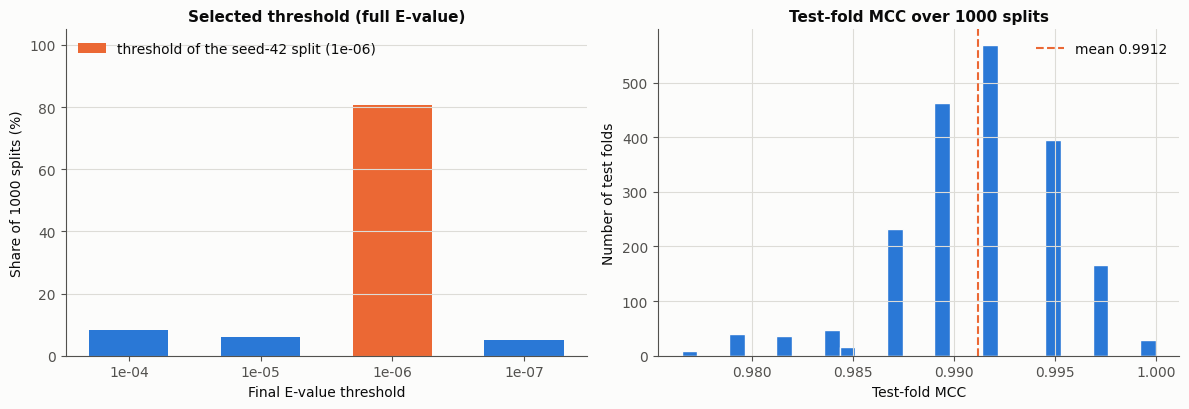


=== domain E-value, 1000 random splits
test-fold MCC: mean 0.9885 ± 0.0041 (min 0.9644, max 1.0000)


,selected on one fold (%),final threshold (%)
1e-09,1,0
1e-08,10.4,0
1e-07,7.6,1.7
1e-06,15.8,48.8
1e-05,34.8,10.8
1e-04,13.6,38.7
1e-03,16.4,0
1e-02,0.2,0


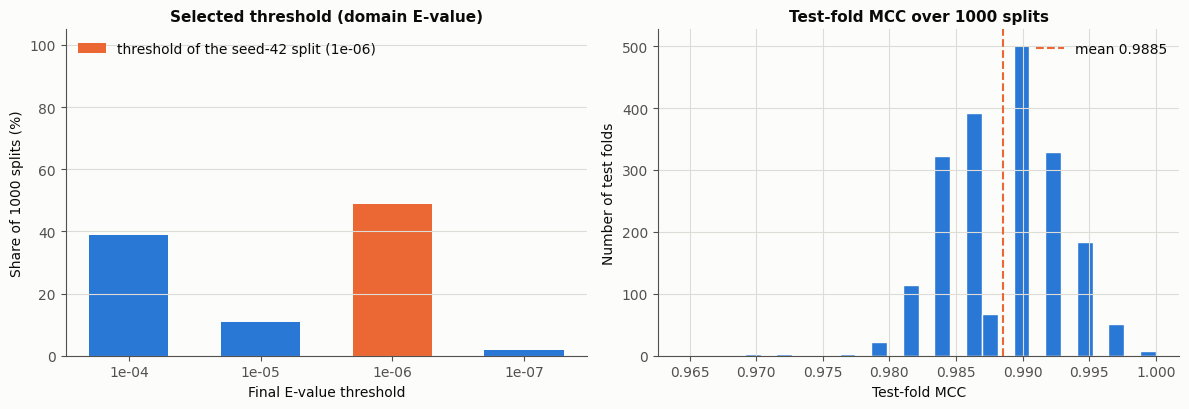

In [16]:
STABILITY_REPEATS = 1000
T = np.array(THRESHOLDS)                       # 1e-1 ... 1e-15, same grid as above


def mcc_curve(pos_e, rel_neg_e, n_neg):
    """MCC at every threshold in T; rel_neg_e = negatives with E <= max(T), n_neg = all negatives."""
    tp = (pos_e[:, None] <= T).sum(0)
    fp = (rel_neg_e[:, None] <= T).sum(0)
    fn, tn = len(pos_e) - tp, n_neg - fp
    denom = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn).astype(float))
    return np.divide(tp * tn - fp * fn, denom, out=np.zeros(len(T)), where=denom > 0)


def pick(mcc):
    """Same rule as best_threshold: middle of the tied best range."""
    tied = np.flatnonzero(np.abs(mcc - mcc.max()) < 1e-12)
    return tied[len(tied) // 2]


STABILITY = {}
for kind, col in (("full", 0), ("domain", 1)):
    pos_e = np.array([pos_hits[i][col] if i in pos_hits else MISSING_EVALUE for i in pos_ids])
    neg_e = np.array([neg_hits[i][col] if i in neg_hits else MISSING_EVALUE for i in neg_ids])
    rel = np.flatnonzero(neg_e <= T.max())     # only these negatives can ever be predicted positive
    n_pos, n_neg = len(pos_e), len(neg_e)
    rng_np = np.random.default_rng(SEED)
    rows = []
    for rep in range(STABILITY_REPEATS):
        p_in1 = np.zeros(n_pos, bool); p_in1[rng_np.permutation(n_pos)[: n_pos // 2]] = True
        n_in1 = np.zeros(n_neg, bool); n_in1[rng_np.permutation(n_neg)[: n_neg // 2]] = True
        folds = {1: (pos_e[p_in1], neg_e[rel][n_in1[rel]], int(n_in1.sum())),
                 2: (pos_e[~p_in1], neg_e[rel][~n_in1[rel]], int((~n_in1).sum()))}
        curves = {k: mcc_curve(*f) for k, f in folds.items()}
        i1, i2 = pick(curves[1]), pick(curves[2])
        final = 10.0 ** round((math.log10(T[i1]) + math.log10(T[i2])) / 2)
        rows.append({"threshold_fold1": T[i1], "threshold_fold2": T[i2], "final_threshold": final,
                     "test_MCC_2": curves[2][i1], "test_MCC_1": curves[1][i2]})
    stab = pd.DataFrame(rows)
    stab.to_csv(D04 / f"{kind}_threshold_stability.csv", index=False)
    test_mcc = pd.concat([stab.test_MCC_1, stab.test_MCC_2])
    freq = stab.final_threshold.value_counts(normalize=True).sort_index(ascending=False)
    per_fold = (pd.concat([stab.threshold_fold1, stab.threshold_fold2])
                .value_counts(normalize=True).sort_index(ascending=False))
    STABILITY[kind] = {"table": stab, "final_freq": freq, "per_fold_freq": per_fold, "test_mcc": test_mcc}
    save_meta(**{f"stability_{kind}": {
        "repeats": STABILITY_REPEATS,
        "final_threshold_frequency": {f"{t:.0e}": round(float(f), 4) for t, f in freq.items()},
        "test_MCC_mean": float(test_mcc.mean()), "test_MCC_sd": float(test_mcc.std()),
        "test_MCC_min": float(test_mcc.min()), "test_MCC_max": float(test_mcc.max())}})

    print(f"\n=== {kind} E-value, {STABILITY_REPEATS} random splits")
    print(f"test-fold MCC: mean {test_mcc.mean():.4f} ± {test_mcc.std():.4f} "
          f"(min {test_mcc.min():.4f}, max {test_mcc.max():.4f})")
    display(pd.DataFrame({"selected on one fold (%)": (per_fold * 100).round(1),
                          "final threshold (%)": (freq * 100).round(1)})
            .fillna(0).rename(index=lambda t: f"{t:.0e}"))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    ax = axes[0]
    labels = [f"{t:.0e}" for t in freq.index]
    ax.bar(labels, freq.values * 100, color=BLUE, width=0.6)
    sel = f"{RESULTS[kind]['threshold']:.0e}"
    if sel in labels:
        ax.bar(sel, freq.values[labels.index(sel)] * 100, color=ORANGE, width=0.6,
               label=f"threshold of the seed-{SEED} split ({sel})")
        ax.legend(frameon=False, loc="upper left")
    ax.set_ylim(0, 105)
    ax.set_xlabel("Final E-value threshold")
    ax.set_ylabel(f"Share of {STABILITY_REPEATS} splits (%)")
    ax.set_title(f"Selected threshold ({kind} E-value)")
    ax.grid(axis="x", visible=False)
    ax = axes[1]
    ax.hist(test_mcc, bins=30, color=BLUE, edgecolor=SURFACE)
    ax.axvline(test_mcc.mean(), color=ORANGE, linestyle="--", linewidth=1.5,
               label=f"mean {test_mcc.mean():.4f}")
    ax.set_xlabel("Test-fold MCC")
    ax.set_ylabel("Number of test folds")
    ax.set_title(f"Test-fold MCC over {STABILITY_REPEATS} splits")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(D04 / f"{kind}_threshold_stability.png", dpi=300)
    plt.show()

### Balanced negative sampling and precision–recall

The negative set is about 1,500 times larger than the positive set, so accuracy and specificity are close to 1 almost by construction, and precision depends strongly on the class ratio. To show the effect of this imbalance, the model is also evaluated at the selected threshold on balanced sets: all test positives plus the same number of randomly drawn negatives, repeated `BALANCED_REPEATS` times. The precision–recall curve compares the full (imbalanced) benchmark with the balanced one (mean precision over the samples).


=== full E-value at threshold 1e-06


,"imbalanced (381 pos / 575,675 neg)","balanced (381 / 381), mean","balanced, sd","balanced, min"
TP,376,376,0,376
FP,1,0,0,0
TN,5.757e+05,381,0,381
FN,5,5,0,5
precision,0.9973,1,0,1
TPR,0.9869,0.9869,0,0.9869
accuracy,1,0.9934,0,0.9934
MCC,0.9921,0.987,0,0.987


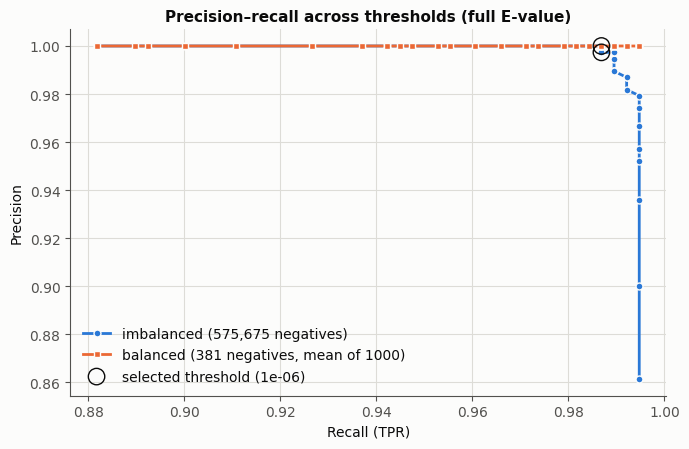


=== domain E-value at threshold 1e-06


,"imbalanced (381 pos / 575,675 neg)","balanced (381 / 381), mean","balanced, sd","balanced, min"
TP,375,375,0,375
FP,1,0,0,0
TN,5.757e+05,381,0,381
FN,6,6,0,6
precision,0.9973,1,0,1
TPR,0.9843,0.9843,0,0.9843
accuracy,1,0.9921,0,0.9921
MCC,0.9908,0.9844,0,0.9844


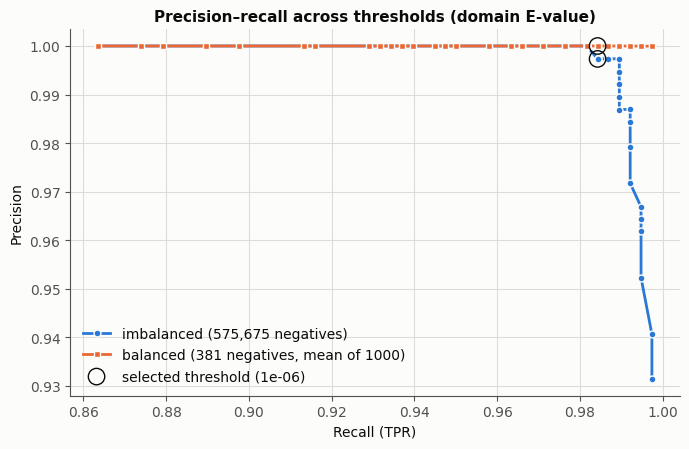

In [17]:
BALANCED_REPEATS = 1000
PR_T = np.array(PLOT_THRESHOLDS)

BALANCED = {}
for kind, col in (("full", 0), ("domain", 1)):
    t = RESULTS[kind]["threshold"]
    pos_e = np.array([pos_hits[i][col] if i in pos_hits else MISSING_EVALUE for i in pos_ids])
    neg_e = np.array([neg_hits[i][col] if i in neg_hits else MISSING_EVALUE for i in neg_ids])
    n_pos = len(pos_e)
    rng_np = np.random.default_rng(SEED)
    samples = np.stack([neg_e[rng_np.choice(len(neg_e), n_pos, replace=False)]
                        for _ in range(BALANCED_REPEATS)])

    per_sample = pd.DataFrame([metrics(pos_e, s, t) for s in samples])
    imbalanced = metrics(pos_e, neg_e, t)
    comp = pd.DataFrame({
        f"imbalanced ({n_pos} pos / {len(neg_e):,} neg)": {
            k: imbalanced[k] for k in ("TP", "FP", "TN", "FN", "precision", "TPR", "accuracy", "MCC")},
        f"balanced ({n_pos} / {n_pos}), mean": per_sample[["TP", "FP", "TN", "FN", "precision", "TPR",
                                                          "accuracy", "MCC"]].mean(),
        "balanced, sd": per_sample[["TP", "FP", "TN", "FN", "precision", "TPR", "accuracy", "MCC"]].std(),
        "balanced, min": per_sample[["TP", "FP", "TN", "FN", "precision", "TPR", "accuracy", "MCC"]].min(),
    }).astype(float).round(4)
    comp.to_csv(D04 / f"{kind}_balanced_vs_imbalanced.csv")

    # precision-recall across thresholds
    tp = (pos_e[:, None] <= PR_T).sum(0)
    recall = tp / n_pos
    fp_all = (neg_e[:, None] <= PR_T).sum(0)
    prec_imb = np.divide(tp, tp + fp_all, out=np.ones(len(PR_T)), where=(tp + fp_all) > 0)
    fp_bal = (samples[:, :, None] <= PR_T).sum(1)                      # repeats x thresholds
    prec_bal = np.divide(tp, tp + fp_bal, out=np.ones(fp_bal.shape), where=(tp + fp_bal) > 0).mean(0)
    pd.DataFrame({"threshold": PR_T, "recall": recall, "precision_imbalanced": prec_imb,
                  "precision_balanced_mean": prec_bal}).to_csv(D04 / f"{kind}_precision_recall.csv", index=False)

    BALANCED[kind] = comp
    save_meta(**{f"balanced_{kind}": {
        "repeats": BALANCED_REPEATS, "threshold": t,
        "precision_mean": float(per_sample.precision.mean()), "precision_sd": float(per_sample.precision.std()),
        "MCC_mean": float(per_sample.MCC.mean()), "MCC_sd": float(per_sample.MCC.std()),
        "FP_mean": float(per_sample.FP.mean())}})

    print(f"\n=== {kind} E-value at threshold {t:.0e}")
    display(comp)

    fig, ax = plt.subplots(figsize=(7, 4.6))
    ax.plot(recall, prec_imb, color=BLUE, marker="o", markeredgecolor=SURFACE,
            label=f"imbalanced ({len(neg_e):,} negatives)")
    ax.plot(recall, prec_bal, color=ORANGE, marker="s", markeredgecolor=SURFACE,
            label=f"balanced ({n_pos} negatives, mean of {BALANCED_REPEATS})")
    k = int(np.argmin(np.abs(np.log10(PR_T) - math.log10(t))))
    ax.scatter([recall[k]], [prec_imb[k]], s=140, facecolor="none", edgecolor=INK, zorder=4,
               label=f"selected threshold ({t:.0e})")
    ax.scatter([recall[k]], [prec_bal[k]], s=140, facecolor="none", edgecolor=INK, zorder=4)
    ax.set_xlabel("Recall (TPR)")
    ax.set_ylabel("Precision")
    ax.set_title(f"Precision–recall across thresholds ({kind} E-value)")
    ax.legend(frameon=False, loc="lower left")
    fig.tight_layout()
    fig.savefig(D04 / f"{kind}_precision_recall.png", dpi=300)
    plt.show()

## Summary of the run

In [18]:
v = META
summary = pd.Series({
    "PDB query date": v.get("pdb_query_date", "unknown"),
    "PDB polymer entities": v["pdb_entities"],
    "MMseqs2 clusters": v["clusters"],
    "Structures aligned / outliers removed": f"{v['structures_round1']} / {len(v['structural_outliers'])}",
    "Final alignment (TM-score, Lcore, Lali)":
        f"{v['mtm_final']['TM-score']:.3f}, {v['mtm_final']['Lcore']:.0f}, {v['mtm_final']['Lali']:.1f}",
    "HMM match states / sequences": f"{v['hmm_length']} / {v['hmm_nseq']}",
    "UniProt release": v.get("uniprot_release", "unknown"),
    "Positives (all / removed / tested)":
        f"{v['uniprot_positives']} / {v['positives_removed']} / {v['positives_test']}",
    "Negatives": v["uniprot_negatives"],
    **{f"{k} E-value: threshold, MCC (whole set)":
           f"{v[f'validation_{k}']['threshold']:.0e}, {v[f'validation_{k}']['whole_dataset']['MCC']:.4f}"
       for k in ("full", "domain")},
    **{f"{k} E-value: test-fold MCC":
           ", ".join(f"{m:.4f}" for m in v[f"validation_{k}"]["test_MCC"]) for k in ("full", "domain")},
    **{f"{k} E-value: {v[f'stability_{k}']['repeats']} random splits, test MCC mean ± sd":
           f"{v[f'stability_{k}']['test_MCC_mean']:.4f} ± {v[f'stability_{k}']['test_MCC_sd']:.4f}"
       for k in ("full", "domain")},
    **{f"{k} E-value: most frequent final threshold (share of splits)":
           (lambda f: f"{max(f, key=f.get)} ({100 * max(f.values()):.1f} %)")(
               v[f"stability_{k}"]["final_threshold_frequency"]) for k in ("full", "domain")},
    **{f"{k} E-value: balanced sets, precision / MCC (mean)":
           f"{v[f'balanced_{k}']['precision_mean']:.4f} / {v[f'balanced_{k}']['MCC_mean']:.4f}"
       for k in ("full", "domain")},
    "Tool versions": ", ".join(f"{t} {ver}" for t, ver in v["tool_versions"].items()),
}, name="value").to_frame()
print("All values are also in", META_FILE.name)
summary

All values are also in run_metadata.json


,value
PDB query date,2026-11-11T17:21:46+00:00
PDB polymer entities,136
MMseqs2 clusters,22
Structures aligned / outliers removed,22 / 0
"Final alignment (TM-score, Lcore, Lali)","0.911, 37, 52.1"
HMM match states / sequences,56 / 22
UniProt release,2026_04
Positives (all / removed / tested),398 / 17 / 381
Negatives,575675
"full E-value: threshold, MCC (whole set)","1e-06, 0.9921"


In [19]:
!cd /content && zip -qr kunitz_hmm_project.zip kunitz_hmm_project -x "*/pdb_raw/*" "*/blastdb/*"
from google.colab import files; files.download("/content/kunitz_hmm_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>